# Phase 4: Recurrent neural network (GRU) decoder

**Goal:** decode hand velocity with a recurrent neural network and compare it with the ridge decoder (R² = 0.61) and the Kalman filter (R² = 0.40) on exactly the same held-out bins.

**Why a recurrent network?** Phase 3b suggested the Kalman filter is held back by two things. Its movement model is linear, which can't capture a reach speeding up and slowing down, and it sees only a short window of spikes. A recurrent network reads spikes one 20 ms bin at a time and carries a memory (its *hidden state*) forward. It learns its own movement dynamics from the data, and those dynamics can be nonlinear. This version uses a **GRU** (gated recurrent unit), a common, compact type of recurrent network. It only looks backward in time, as a real-time decoder must.

**Steps**
1. Load the data and reuse the same 80 training and 20 test trials. Set aside 16 of the training trials as a **validation** set for tuning.
2. Build each trial's input sequence: spike counts from 400 ms before the window through its end.
3. Tune the network's size and dropout on the validation set, with early stopping.
4. Train the final network on all 80 training trials five times, with different random seeds, and test it.
5. Refit ridge and the Kalman filter, then compare all three on identical test bins.

In [1]:
import torch          # import PyTorch first: on Windows, importing it after other libraries can fail (WinError 1114)
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

sys.path.insert(0, os.path.abspath(".."))
from src.data import (BIN_MS, load_dataset, get_trials, build_features, build_sequences,
                      build_rnn_sequences, pad_sequences)
from src.decoders import KalmanDecoder, fit_ridge
from src.rnn import train_gru, predict_gru

print("PyTorch", torch.__version__)
DATA_PATH = "../data/000140/sub-Jenkins/"
HISTORY_MS = 400                          # spiking the network sees before the window starts
HIDDEN_SIZES = [32, 64, 128]              # number of hidden units to try
DROPOUTS = [0.0, 0.3]                     # fraction of inputs randomly silenced during training
N_SEEDS = 5                               # final networks trained with different random starts
RIDGE_HISTORY_MS = 400                    # best ridge setting from Phase 3
KALMAN = {"noise": "shrinkage", "lag_ms": 160, "window_bins": 3}   # best Kalman setting from Phase 3b
os.makedirs("../figures", exist_ok=True)

PyTorch 2.14.1+cpu


## 1. Load the data and make the splits

The test trials are the same as in every earlier phase (random seed 0). From the 80 training trials, 16 are set aside as a **validation set**. It is used to choose the network's settings and to decide when to stop training. The test trials stay untouched until the end.

In [2]:
dataset = load_dataset(DATA_PATH)
trials = get_trials(dataset, history_ms=HISTORY_MS)

trial_ids = np.unique(trials["trial_id"])
test_ids = np.random.default_rng(0).choice(trial_ids, size=20, replace=False)   # same as Phases 2-3
train_ids = np.setdiff1d(trial_ids, test_ids)
val_ids = np.random.default_rng(1).choice(train_ids, size=16, replace=False)
fit_ids = np.setdiff1d(train_ids, val_ids)
print(len(fit_ids), "fitting +", len(val_ids), "validation =", len(train_ids), "training trials |",
      len(test_ids), "test trials")

64 fitting + 16 validation = 80 training trials | 20 test trials


## 2. Build the input sequences

Each trial becomes one sequence of 20 ms bins, starting 400 ms before the decoding window. The **inputs** are the spike counts of all 142 neurons. The **targets** are hand velocity (x, y), scored only inside the window.

**Standardizing:** each neuron's counts and each velocity component are rescaled to mean 0 and standard deviation 1, using training trials only. Neural networks train much more reliably on inputs of similar scale. A floor on each neuron's spread (0.1 spikes per bin) keeps very quiet neurons from producing huge values.

In [3]:
seqs = {s["trial_id"]: s for s in build_rnn_sequences(trials, HISTORY_MS)}

def fit_scaler(ids):
    # Means and spreads from the given (training) trials only
    S = np.vstack([seqs[i]["S"] for i in ids])
    V = np.vstack([seqs[i]["V"][seqs[i]["scored"]] for i in ids])
    return {"s_mean": np.nanmean(S, axis=0), "s_std": np.maximum(np.nanstd(S, axis=0), 0.1),
            "v_mean": V.mean(axis=0), "v_std": V.std(axis=0)}

def make_arrays(ids, sc):
    # Standardize, then stack into (trials, bins, ...) arrays padded to equal length
    scaled = [{**seqs[i], "S": (seqs[i]["S"] - sc["s_mean"]) / sc["s_std"],
               "V": (seqs[i]["V"] - sc["v_mean"]) / sc["v_std"]} for i in ids]
    return pad_sequences(scaled)

def to_velocity(Y_std, sc):
    # Undo the velocity standardization
    return Y_std * sc["v_std"] + sc["v_mean"]

sc_fit = fit_scaler(fit_ids)
X_fit, Y_fit, M_fit, _ = make_arrays(fit_ids, sc_fit)
X_val, Y_val, M_val, _ = make_arrays(val_ids, sc_fit)
print("inputs:", X_fit.shape, "(trials, bins, neurons) | scored bins:", int(M_fit.sum()), "fitting,",
      int(M_val.sum()), "validation")

inputs: (64, 55, 142) (trials, bins, neurons) | scored bins: 2240 fitting, 560 validation


## 3. Tune the network on the validation set

Six versions are tried: 32, 64, or 128 hidden units, each with and without dropout. Each is trained on the 64 fitting trials. After every pass through the data (an **epoch**), its error is checked on the 16 validation trials. Training stops once validation error hasn't improved for 50 epochs (**early stopping**), and the best epoch's weights are kept. This guards against **overfitting**: memorizing the training trials instead of learning patterns that generalize.

This cell takes a few minutes.

In [4]:
rows, histories = [], {}
for h in HIDDEN_SIZES:
    for d in DROPOUTS:
        model, hist = train_gru(X_fit, Y_fit, M_fit, X_val, Y_val, M_val, n_hidden=h, dropout=d, seed=0)
        pred = to_velocity(predict_gru(model, X_val), sc_fit)
        r2x, r2y = r2_score(to_velocity(Y_val, sc_fit)[M_val], pred[M_val], multioutput="raw_values")
        rows.append({"hidden": h, "dropout": d, "best_epoch": hist["best_epoch"],
                     "val_r2_x": r2x, "val_r2_y": r2y, "val_r2": (r2x + r2y) / 2})
        histories[(h, d)] = hist
tuning = pd.DataFrame(rows)
print(tuning.round(3).to_string(index=False))

best = tuning.loc[tuning["val_r2"].idxmax()]
HIDDEN, DROPOUT, EPOCHS = int(best["hidden"]), float(best["dropout"]), int(best["best_epoch"])
print(f"\nChosen: {HIDDEN} hidden units, dropout {DROPOUT}, {EPOCHS} epochs (validation R² = {best['val_r2']:.3f})")

 hidden  dropout  best_epoch  val_r2_x  val_r2_y  val_r2
     32      0.0          24     0.422     0.300   0.361
     32      0.3         459     0.840     0.837   0.839
     64      0.0          56     0.631     0.416   0.524
     64      0.3         173     0.837     0.785   0.811
    128      0.0          44     0.653     0.577   0.615
    128      0.3         146     0.880     0.843   0.861

Chosen: 128 hidden units, dropout 0.3, 146 epochs (validation R² = 0.861)


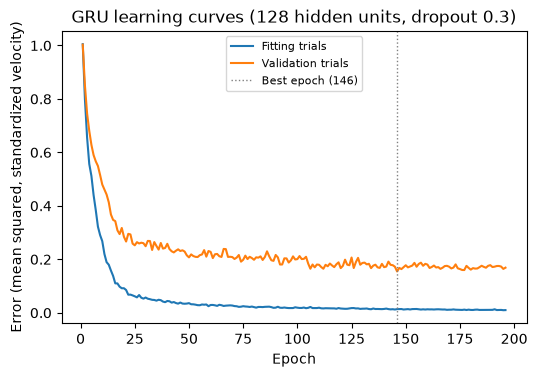

In [5]:
# Figure 11: learning curves for the chosen network
hist = histories[(HIDDEN, DROPOUT)]
plt.figure(figsize=(6, 3.8))
plt.plot(range(1, len(hist["train_loss"]) + 1), hist["train_loss"], label="Fitting trials")
plt.plot(range(1, len(hist["val_loss"]) + 1), hist["val_loss"], label="Validation trials")
plt.axvline(EPOCHS, color="gray", ls=":", lw=1, label=f"Best epoch ({EPOCHS})")
plt.xlabel("Epoch"); plt.ylabel("Error (mean squared, standardized velocity)")
plt.title(f"GRU learning curves ({HIDDEN} hidden units, dropout {DROPOUT})")
plt.legend(fontsize=8)
plt.savefig("../figures/11_gru_learning_curves.png", dpi=150, bbox_inches="tight")

## 4. Train the final network and test it

The chosen network is retrained on all 80 training trials for the number of epochs early stopping picked. Training starts from random weights, so the result varies from run to run. It is therefore trained **five times with different random seeds**. Each run is reported, and so is the result of averaging the five networks' predictions (an **ensemble**).

In [6]:
sc_all = fit_scaler(train_ids)
X_tr, Y_tr, M_tr, _ = make_arrays(train_ids, sc_all)
X_te, Y_te, M_te, T_te = make_arrays(test_ids, sc_all)
true_te = to_velocity(Y_te, sc_all)

preds, seed_rows = [], []
for seed in range(N_SEEDS):
    model, _ = train_gru(X_tr, Y_tr, M_tr, n_hidden=HIDDEN, dropout=DROPOUT, fixed_epochs=EPOCHS, seed=seed)
    P = to_velocity(predict_gru(model, X_te), sc_all)
    preds.append(P)
    rx, ry = r2_score(true_te[M_te], P[M_te], multioutput="raw_values")
    seed_rows.append({"seed": seed, "R² x": rx, "R² y": ry, "R² mean": (rx + ry) / 2})
seed_results = pd.DataFrame(seed_rows)
print(seed_results.round(3).to_string(index=False))
print(f"\nSingle networks: R² = {seed_results['R² mean'].mean():.3f} ± {seed_results['R² mean'].std():.3f} (mean ± SD over {N_SEEDS} seeds)")

ensemble = np.mean(preds, axis=0)
gru_parts = []
for i, tid in enumerate(test_ids):
    m = M_te[i]
    gru_parts.append(pd.DataFrame({"trial": tid, "t": T_te[i][m].astype(int),
                                   "true_x": true_te[i][m, 0], "true_y": true_te[i][m, 1],
                                   "gru_x": ensemble[i][m, 0], "gru_y": ensemble[i][m, 1]}))
gru_df = pd.concat(gru_parts, ignore_index=True)

 seed  R² x  R² y  R² mean
    0 0.811 0.606    0.709
    1 0.838 0.635    0.736
    2 0.820 0.652    0.736
    3 0.824 0.642    0.733
    4 0.820 0.654    0.737

Single networks: R² = 0.730 ± 0.012 (mean ± SD over 5 seeds)


## 5. Compare with ridge and the Kalman filter on identical bins

Ridge (400 ms of history) and the Kalman filter (shrinkage noise, 160 ms lag, 60 ms window) are refit with their best settings from Phases 3 and 3b. All three decoders are then scored on the same test bins. The ridge fit takes several minutes.

In [7]:
# Ridge, 400 ms of spike history
X_all, y, groups, t_ms = build_features(trials, n_lags=RIDGE_HISTORY_MS // BIN_MS)
train, test = np.isin(groups, train_ids), np.isin(groups, test_ids)
ridge = fit_ridge(X_all[train], y[train], groups[train])
ridge_pred = ridge.predict(X_all[test])
ridge_df = pd.DataFrame({"trial": groups[test], "t": t_ms[test],
                         "ridge_x": ridge_pred[:, 0], "ridge_y": ridge_pred[:, 1]})

# Kalman filter, best Phase 3b settings
kseqs = {s["trial_id"]: s for s in build_sequences(trials, KALMAN["lag_ms"], KALMAN["window_bins"])}
kalman = KalmanDecoder(noise=KALMAN["noise"]).fit([kseqs[i] for i in train_ids])
kal_parts = []
for tid in test_ids:
    est = kalman.predict(kseqs[tid]["Z"])
    kal_parts.append(pd.DataFrame({"trial": tid, "t": kseqs[tid]["t"], "kal_x": est[:, 2], "kal_y": est[:, 3]}))
kal_df = pd.concat(kal_parts, ignore_index=True)

allp = (gru_df.merge(ridge_df, on=["trial", "t"]).merge(kal_df, on=["trial", "t"])
        .sort_values(["trial", "t"]).reset_index(drop=True))

def r2_row(name, px, py):
    rx, ry = r2_score(allp["true_x"], allp[px]), r2_score(allp["true_y"], allp[py])
    return {"decoder": name, "R² x": rx, "R² y": ry, "R² mean": (rx + ry) / 2}

comparison = pd.DataFrame([
    r2_row(f"Ridge ({RIDGE_HISTORY_MS} ms history)", "ridge_x", "ridge_y"),
    r2_row(f"Kalman ({KALMAN['noise']}, {KALMAN['lag_ms']} ms lag)", "kal_x", "kal_y"),
    r2_row(f"GRU ({HIDDEN} units, {N_SEEDS}-seed ensemble)", "gru_x", "gru_y"),
])
print(f"{len(allp)} test bins from {allp['trial'].nunique()} held-out trials\n")
print(comparison.round(3).to_string(index=False))

700 test bins from 20 held-out trials

                         decoder  R² x  R² y  R² mean
          Ridge (400 ms history) 0.686 0.525    0.606
  Kalman (shrinkage, 160 ms lag) 0.508 0.301    0.405
GRU (128 units, 5-seed ensemble) 0.845 0.674    0.759


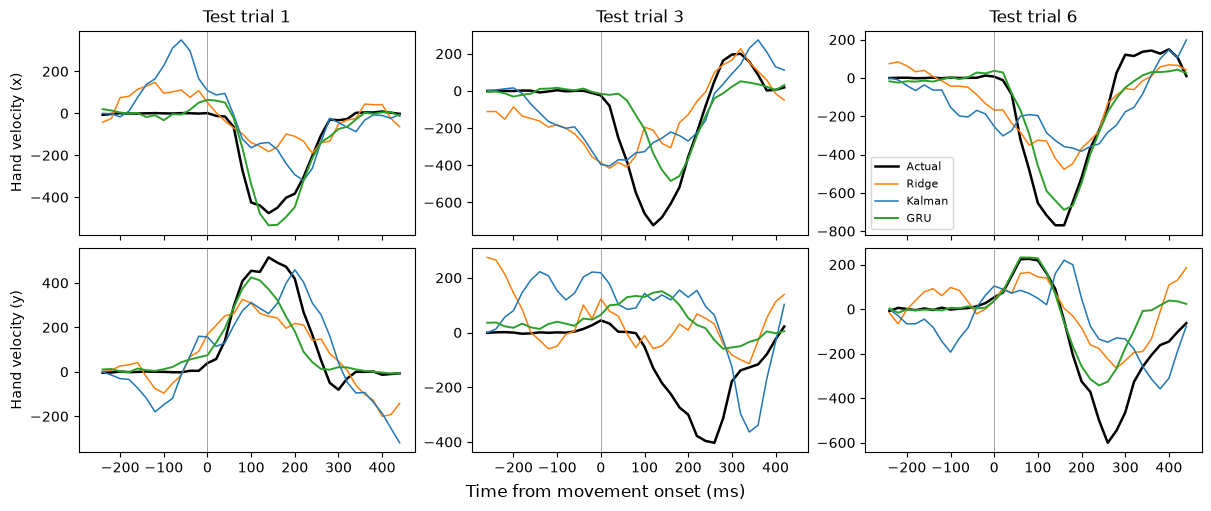

In [8]:
# Figure 12: decoded vs. actual velocity on three test trials, all three decoders
show_ids = sorted(allp["trial"].unique())[:3]
styles = [("true", "Actual", "black", 1.8), ("ridge", "Ridge", "tab:orange", 1.1),
          ("kal", "Kalman", "tab:blue", 1.1), ("gru", "GRU", "tab:green", 1.4)]
fig, axes = plt.subplots(2, 3, figsize=(12, 5), sharex=True, constrained_layout=True)
for col, tid in enumerate(show_ids):
    d = allp[allp["trial"] == tid]
    for row, k in enumerate(["x", "y"]):
        ax = axes[row, col]
        for key, label, color, lw in styles:
            ax.plot(d["t"], d[f"{key}_{k}"], color=color, lw=lw, label=label)
        ax.axvline(0, color="gray", lw=0.5)
        if col == 0:
            ax.set_ylabel(f"Hand velocity ({k})")
        if row == 0:
            ax.set_title(f"Test trial {tid}")
axes[0, -1].legend(fontsize=8)
fig.supxlabel("Time from movement onset (ms)")
plt.savefig("../figures/12_decoder_comparison_velocity.png", dpi=150, bbox_inches="tight")

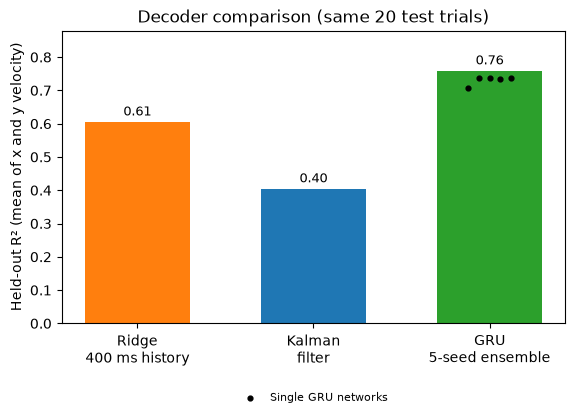

In [9]:
# Figure 13: held-out R² by decoder; dots show the five individual GRU networks
fig, ax = plt.subplots(figsize=(6.5, 3.8))
colors = ["tab:orange", "tab:blue", "tab:green"]
labels = ["Ridge\n400 ms history", "Kalman\nfilter", "GRU\n5-seed ensemble"]
bars = ax.bar(labels, comparison["R² mean"], color=colors, width=0.6)
for bar, v in zip(bars, comparison["R² mean"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
xg = bars[2].get_x() + bars[2].get_width() / 2
ax.scatter(np.full(N_SEEDS, xg) + np.linspace(-0.12, 0.12, N_SEEDS), seed_results["R² mean"],
           color="black", s=12, zorder=3, label="Single GRU networks")
ax.set_ylabel("Held-out R² (mean of x and y velocity)")
ax.set_title("Decoder comparison (same 20 test trials)")
ax.set_ylim(0, min(1.0, comparison["R² mean"].max() + 0.12))
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.savefig("../figures/13_decoder_comparison_r2.png", dpi=150, bbox_inches="tight")

## Results to record

**How to read the results:**
- **GRU vs. ridge:** if the GRU wins, learning nonlinear dynamics from long spike histories helps, which supports the remaining Phase 3b explanations. If ridge still wins or ties, the most likely reason is the small training set (80 trials): neural networks usually need more data to beat well-regularized linear models.
- **Seed spread:** if the five single networks vary widely, the result is sensitive to random initialization, a sign of limited data. Averaging them (the ensemble) usually helps.
- **Learning curves (Figure 11):** validation error that bottoms out and then rises while fitting error keeps falling is overfitting. Early stopping chose the epoch at that bottom.

In [10]:
r, k, g = comparison.iloc[0], comparison.iloc[1], comparison.iloc[2]
print(f"GRU ({HIDDEN} hidden units, dropout {DROPOUT}, {EPOCHS} epochs), {N_SEEDS}-seed ensemble: held-out R² = {g['R² mean']:.2f} "
      f"(x = {g['R² x']:.2f}, y = {g['R² y']:.2f}); single networks {seed_results['R² mean'].mean():.2f} ± {seed_results['R² mean'].std():.2f}")
print(f"Ridge: {r['R² mean']:.2f} | Kalman: {k['R² mean']:.2f}  (same {len(allp)} test bins)")

GRU (128 hidden units, dropout 0.3, 146 epochs), 5-seed ensemble: held-out R² = 0.76 (x = 0.84, y = 0.67); single networks 0.73 ± 0.01
Ridge: 0.61 | Kalman: 0.40  (same 700 test bins)
